# Analyzing a splicing variant

Variants can alter *how* a gene is spliced, not only how much it is expressed. This tutorial uses AlphaGenome 2 to predict, visualize, and score a splicing variant: chr22:36201698:A>C at *APOL4* in sigmoid colon (`UBERON:0001159`), an example highlighted in the [AlphaGenome 1 quick start (legacy)](https://www.alphagenomedocs.com/colabs/v1/quick_start.html) and {cite:t}`alphagenome`.

Key activities:
- Inspect how AlphaGenome 2 represents splicing outputs and verify their measurement status in sigmoid colon.
- Predict REF and ALT tracks for `RNA_SEQ`, `SPLICE_SITES`, `SPLICE_SITE_USAGE`, and `SPLICE_JUNCTIONS`.
- Plot negative-strand junction arcs (`plot_components.Sashimi`) alongside overlaid splice site usage and RNA-seq coverage.
- Score the variant across the recommended splicing and RNA-seq variant scorers.

## Set up

In [ ]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

In [1]:
# @title Imports
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.models.v2 import dna_client
from alphagenome.models.v2 import variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)), then initialize the client:

In [2]:
dna_model = dna_client.create(colab_utils.get_api_key())

## Splicing outputs

AlphaGenome 2 predicts splicing with three specialized output types, alongside bulk RNA-seq coverage, which also captures splicing patterns (see [Model output metadata](https://www.alphagenomedocs.com/exploring_model_metadata.html)):

| Output type | Resolution | Description |
| :--- | :--- | :--- |
| `SPLICE_SITES` | 1 bp | Condition-specific classification probabilities across 5 channels (donor and acceptor on each strand plus non-splice-site padding), derived per condition from its RNA-seq splicing assays. |
| `SPLICE_SITE_USAGE` | 1 bp | Condition-specific fraction of transcripts spliced at each donor or acceptor site per RNA-seq track. |
| `SPLICE_JUNCTIONS` | Junction pairs | Condition-specific split-read counts spanning donor-acceptor intron pairs. |

Check the `imputation_mode` status of `RNA_SEQ` and the three splicing output types in sigmoid colon (`UBERON:0001159`) via `dna_model.supported_conditions()`:

In [3]:
condition = 'UBERON:0001159'  # Sigmoid colon.

dna_model.supported_conditions().set_index('condition').loc[
    condition,
    ['rna_seq', 'splice_sites', 'splice_site_usage', 'splice_junctions'],
]

rna_seq              observed
splice_sites         observed
splice_site_usage    observed
splice_junctions     observed
Name: UBERON:0001159, dtype: object

Load GENCODE gene annotations and construct a `TranscriptExtractor` across **all** protein-coding transcripts (rather than restricting to MANE Select alone) so alternative *APOL4* isoforms are displayed:

In [4]:
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf_transcripts = gene_annotation.filter_protein_coding(gtf)
transcript_extractor = transcript_utils.TranscriptExtractor(gtf_transcripts)

## Predict the variant

Center a 1 Mb sequence window (`dna_client.SEQUENCE_LENGTH_1MB`) around chr22:36201698:A>C (`genome.Variant`) and predict `RNA_SEQ`, `SPLICE_SITES`, `SPLICE_SITE_USAGE`, and `SPLICE_JUNCTIONS` for both REF and ALT alleles:

In [5]:
variant = genome.Variant(
    chromosome='chr22',
    position=36201698,
    reference_bases='A',
    alternate_bases='C',
)
interval = variant.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)

output = dna_model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.SPLICE_SITES,
        dna_client.OutputType.SPLICE_SITE_USAGE,
        dna_client.OutputType.SPLICE_JUNCTIONS,
    ],
    condition=condition,
)

## Visualize splicing and expression changes

We keep observed negative-strand GTEx tracks (`output.reference.filter_to_observed()`) and plot REF and ALT junction arcs (`plot_components.Sashimi`), splice site usage, and RNA-seq coverage across *APOL4*:

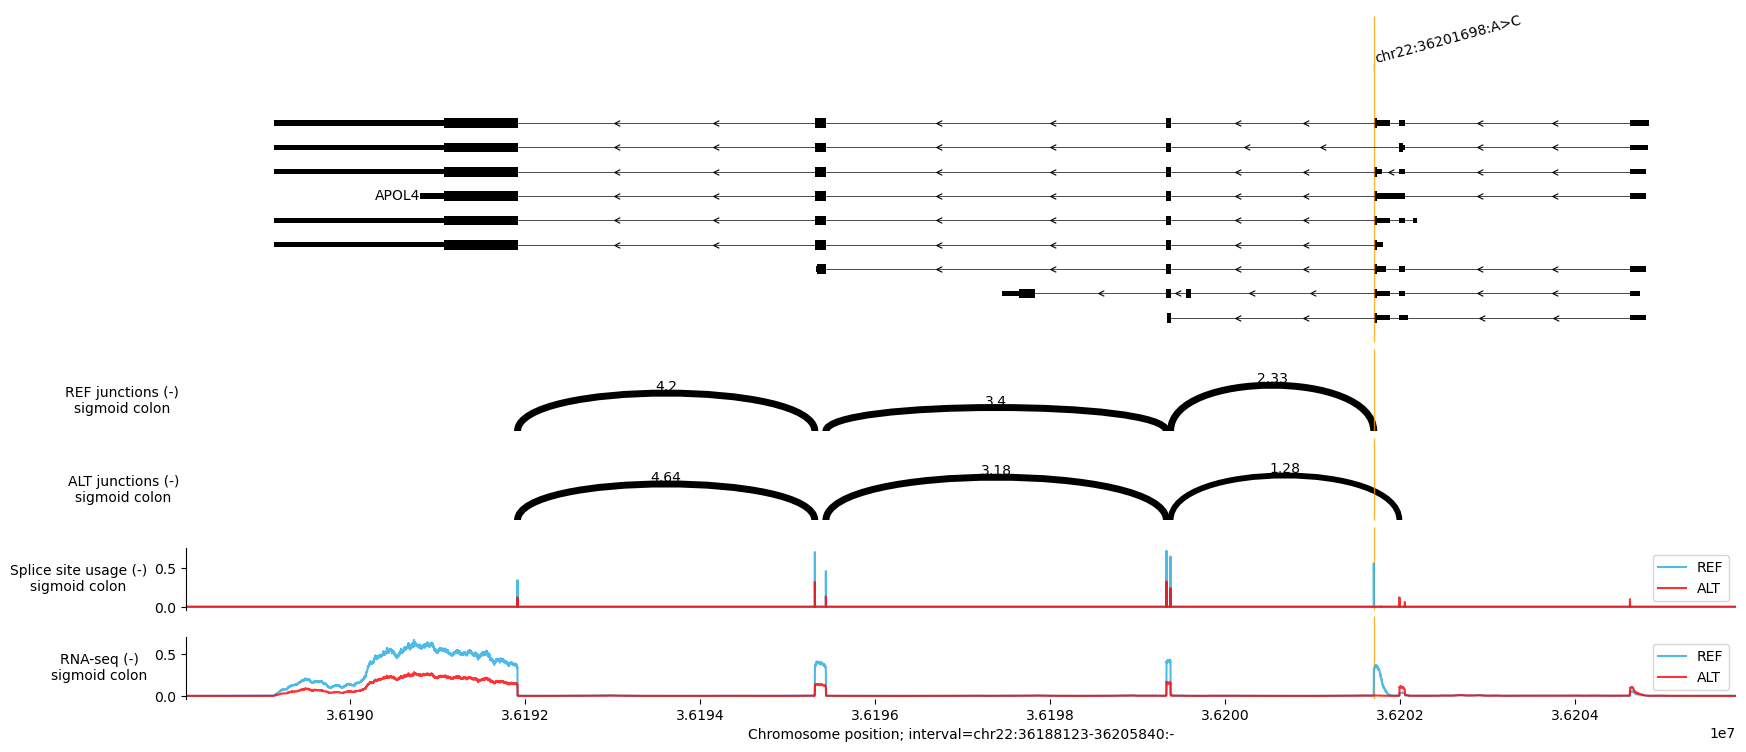

In [6]:
plot_interval = gene_annotation.get_gene_interval(gtf, gene_symbol='APOL4').pad(
    1000, 1000
)
obs_ref = output.reference.filter_to_observed()
obs_alt = output.alternate.filter_to_observed()

ref_j = obs_ref.splice_junctions.filter_to_strand('-')
alt_j = obs_alt.splice_junctions.filter_to_strand('-')
gtex_j_mask = (ref_j.metadata['data_source'] == 'gtex').values

ref_ssu = obs_ref.splice_site_usage.filter_to_negative_strand().slice_by_interval(
    plot_interval, match_resolution=True
)
alt_ssu = obs_alt.splice_site_usage.filter_to_negative_strand().slice_by_interval(
    plot_interval, match_resolution=True
)
gtex_ssu_mask = (ref_ssu.metadata['data_source'] == 'gtex').values

ref_rna = obs_ref.rna_seq.filter_to_negative_strand().slice_by_interval(
    plot_interval, match_resolution=True
)
alt_rna = obs_alt.rna_seq.filter_to_negative_strand().slice_by_interval(
    plot_interval, match_resolution=True
)
rna_mask = (
    (ref_rna.metadata['Assay title'] == 'polyA plus RNA-seq')
    & (ref_rna.metadata['endedness'] == 'paired')
).values

transcripts = transcript_extractor.extract(interval)
ref_alt_colors = {'REF': '#22AAE1', 'ALT': 'red'}

plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.Sashimi(
            ref_j.filter_tracks(gtex_j_mask),
            ylabel_template='REF junctions ({strand})\n{biosample_name}',
        ),
        plot_components.Sashimi(
            alt_j.filter_tracks(gtex_j_mask),
            ylabel_template='ALT junctions ({strand})\n{biosample_name}',
        ),
        plot_components.OverlaidTracks(
            tdata={
                'REF': ref_ssu.filter_tracks(gtex_ssu_mask),
                'ALT': alt_ssu.filter_tracks(gtex_ssu_mask),
            },
            colors=ref_alt_colors,
            ylabel_template='Splice site usage ({strand})\n{biosample_name}',
        ),
        plot_components.OverlaidTracks(
            tdata={
                'REF': ref_rna.filter_tracks(rna_mask),
                'ALT': alt_rna.filter_tracks(rna_mask),
            },
            colors=ref_alt_colors,
            ylabel_template='RNA-seq ({strand})\n{biosample_name}',
        ),
    ],
    interval=plot_interval,
    annotations=[plot_components.VariantAnnotation([variant], alpha=0.8)],
)
plt.show()

On the negative strand at *APOL4*, AlphaGenome 2 predicts that the ALT allele (C at chr22:36201698) suppresses the canonical splice junction adjacent to the variant, shifts split reads toward an upstream exon-skipping junction, reduces predicted donor splice-site usage at the disrupted exon boundary, and lowers exon RNA-seq coverage across *APOL4*.

## Score the variant

Quantify these effects across all three splicing scorers (`SPLICE_SITES`, `SPLICE_SITE_USAGE`, `SPLICE_JUNCTIONS`) together with `RNA_SEQ` from `variant_scorers.RECOMMENDED_VARIANT_SCORERS`, then format the per-gene results with `variant_scorers.tidy_scores`:

In [7]:
splicing_scorers = [
    variant_scorers.RECOMMENDED_VARIANT_SCORERS[name]
    for name in ('SPLICE_SITES', 'SPLICE_SITE_USAGE', 'SPLICE_JUNCTIONS')
]
scores = dna_model.score_variant(
    interval=interval,
    variant=variant,
    variant_scorers=[
        *splicing_scorers,
        variant_scorers.RECOMMENDED_VARIANT_SCORERS['RNA_SEQ'],
    ],
    condition=condition,
)
tidy = variant_scorers.tidy_scores(scores, match_gene_strand=True)
tidy[tidy['gene_name'] == 'APOL4']

,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,track_name,track_strand,imputation_mode,biosample_curie,biosample_type,biosample_name,splice_site_type,Assay title,data_source,data_pipeline,genetically_modified,endedness,raw_score
0,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,None,None,SPLICE_SITES,"GeneMaskSplicingScorer(requested_output=SPLICE_SITES, width=None)",UBERON:0001159_donor,.,observed,UBERON:0001159,tissue,sigmoid colon,donor,NaN,NaN,NaN,NaN,NaN,0.895063
1,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,None,None,SPLICE_SITES,"GeneMaskSplicingScorer(requested_output=SPLICE_SITES, width=None)",UBERON:0001159_acceptor,.,observed,UBERON:0001159,tissue,sigmoid colon,acceptor,NaN,NaN,NaN,NaN,NaN,0.255946
2,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,None,None,SPLICE_SITE_USAGE,"GeneMaskSplicingScorer(requested_output=SPLICE_SITE_USAGE, width=None)",UBERON:0001159_polyA plus RNA-seq-encode,.,observed,UBERON:0001159,tissue,sigmoid colon,NaN,polyA plus RNA-seq,encode,encode,NaN,NaN,0.593331
3,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,None,None,SPLICE_SITE_USAGE,"GeneMaskSplicingScorer(requested_output=SPLICE_SITE_USAGE, width=None)",UBERON:0001159_polyA plus RNA-seq-gtex,.,observed,UBERON:0001159,tissue,sigmoid colon,NaN,polyA plus RNA-seq,gtex,recount3,NaN,NaN,0.556729
4,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,None,None,SPLICE_SITE_USAGE,"GeneMaskSplicingScorer(requested_output=SPLICE_SITE_USAGE, width=None)",UBERON:0001159_total RNA-seq-encode,.,observed,UBERON:0001159,tissue,sigmoid colon,NaN,total RNA-seq,encode,encode,NaN,NaN,0.566698
5,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,36199376,36201699,SPLICE_JUNCTIONS,SpliceJunctionScorer(),UBERON:0001159_polyA plus RNA-seq-encode,.,observed,UBERON:0001159,tissue,sigmoid colon,NaN,polyA plus RNA-seq,encode,encode,NaN,NaN,5.640625
6,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,36199376,36201699,SPLICE_JUNCTIONS,SpliceJunctionScorer(),UBERON:0001159_polyA plus RNA-seq-gtex,.,observed,UBERON:0001159,tissue,sigmoid colon,NaN,polyA plus RNA-seq,gtex,recount3,NaN,NaN,5.792969
7,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,36199376,36201699,SPLICE_JUNCTIONS,SpliceJunctionScorer(),UBERON:0001159_total RNA-seq-encode,.,observed,UBERON:0001159,tissue,sigmoid colon,NaN,total RNA-seq,encode,encode,NaN,NaN,5.699219
13,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,None,None,RNA_SEQ,"GeneMaskLFCScorer(requested_output=RNA_SEQ, aggregation_type=DIFF_MEAN)",UBERON:0001159_polyA plus RNA-seq-encode-paired-ended,.,observed,UBERON:0001159,tissue,sigmoid colon,NaN,polyA plus RNA-seq,encode,encode,False,paired,-0.893399
14,chr22:36201698:A>C,chr22:35677410-36725986:.,ENSG00000100336,APOL4,protein_coding,-,None,None,RNA_SEQ,"GeneMaskLFCScorer(requested_output=RNA_SEQ, aggregation_type=DIFF_MEAN)",UBERON:0001159_polyA plus RNA-seq-encode-single-ended,.,imputed_supported,UBERON:0001159,tissue,sigmoid colon,NaN,polyA plus RNA-seq,NaN,encode,NaN,single,-1.041781


## Combine the splicing scores

Following the splicing variant benchmarks in {cite:t}`alphagenome`, we can combine the maximum magnitude across genes and observed tracks for each of the three splicing output types into a single merged splicing score per variant:

$$
\text{alphagenome\_splicing} = \max|\text{splice\_sites}| + \max|\text{splice\_site\_usage}| + \frac{\max|\text{splice\_junctions}|}{5}
$$

Giving weight 0.2 (1 / 5) to `SPLICE_JUNCTIONS` accounts for the larger scale of junction log-fold changes relative to probability differences ([0, 1]).

```{note}
- **Multi-tissue ensembling**: Each AlphaGenome 2 call scores one `condition` at a time. In **AlphaGenome 1** (`alphagenome.models.v1`), `score_variant` evaluates all observed biosamples simultaneously; scoring or taking the maximum across multiple relevant tissues can improve sensitivity for tissue-restricted splice variants.
- **Imputed splicing tracks**: Filter to `imputation_mode == "observed"` when available, as imputed `SPLICE_SITE_USAGE` and `SPLICE_JUNCTIONS` tracks carry additional caveats; see [Navigating imputed tracks](https://www.alphagenomedocs.com/user_guides/imputation.html).
```

In [8]:
def compute_merged_splicing_score(df: pd.DataFrame) -> pd.DataFrame:
  """Computes the merged splicing score across observed tracks per variant."""
  obs_df = df[df['imputation_mode'] == 'observed'].copy()
  obs_df['variant_id'] = obs_df['variant_id'].map(str)
  obs_df['abs_raw_score'] = obs_df['raw_score'].abs()
  max_scores = (
      obs_df.groupby(['variant_id', 'output_type'])['abs_raw_score']
      .max()
      .reset_index()
      .pivot(index='variant_id', columns='output_type', values='abs_raw_score')
      .fillna(0.0)
  )
  max_scores['alphagenome_splicing'] = (
      max_scores.get('SPLICE_SITES', 0.0)
      + max_scores.get('SPLICE_SITE_USAGE', 0.0)
      + max_scores.get('SPLICE_JUNCTIONS', 0.0) / 5.0
  )
  return max_scores.reset_index()


compute_merged_splicing_score(tidy)

output_type,variant_id,RNA_SEQ,SPLICE_JUNCTIONS,SPLICE_SITES,SPLICE_SITE_USAGE,alphagenome_splicing
0,chr22:36201698:A>C,1.59581,5.792969,0.895063,0.593331,2.646988


## Next steps

- See [Deriving PSI values from splice junctions](https://www.alphagenomedocs.com/colabs/v1/deriving_PSI_values.html) to compute percent spliced in (PSI5 and PSI3) ratios from `JunctionData` predictions.
- Explore additional track and junction plotting layouts in [Plotting predictions](https://www.alphagenomedocs.com/colabs/v2/plotting_predictions.html).
- Read [How variant scoring works](https://www.alphagenomedocs.com/variant_scoring.html) for details on spatial aggregation and gene masks across scorers.